In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

print("TensorFlow Version:", tf.__version__)
print("ANN Project Environment Ready!")

TensorFlow Version: 2.21.0
ANN Project Environment Ready!


In [2]:
from google.colab import files

uploaded = files.upload()

Saving IBM_HR_Attrition.csv.csv to IBM_HR_Attrition.csv.csv


In [3]:
import pandas as pd

df = pd.read_csv("IBM_HR_Attrition.csv.csv")

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset Loaded Successfully!
Dataset Shape: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [4]:
print("DATASET INFORMATION")
print("=" * 40)

df.info()

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nAttrition Distribution:")
print(df["Attrition"].value_counts())

print("\nAttrition Percentage:")
print(df["Attrition"].value_counts(normalize=True) * 100)

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobL

In [5]:
df["Attrition"] = df["Attrition"].map({
    "No": 0,
    "Yes": 1
})

print("Target Encoding Completed!")
print(df["Attrition"].value_counts())

print("\nTarget Data Type:", df["Attrition"].dtype)

Target Encoding Completed!
Attrition
0    1233
1     237
Name: count, dtype: int64

Target Data Type: int64


In [6]:
columns_to_drop = [
    "EmployeeCount",
    "EmployeeNumber",
    "Over18",
    "StandardHours"
]

df = df.drop(columns=columns_to_drop)

print("Unnecessary Columns Removed!")
print("Updated Dataset Shape:", df.shape)
print("\nRemaining Columns:")
print(df.columns.tolist())

Unnecessary Columns Removed!
Updated Dataset Shape: (1470, 31)

Remaining Columns:
['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


In [7]:
X = df.drop("Attrition", axis=1)
y = df["Attrition"]

print("Features and Target Separated!")
print("X Shape:", X.shape)
print("y Shape:", y.shape)

print("\nFeature Columns:")
print(X.columns.tolist())

Features and Target Separated!
X Shape: (1470, 30)
y Shape: (1470,)

Feature Columns:
['Age', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Data Splitting Completed!")
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Data Splitting Completed!
Training Features: (1176, 30)
Testing Features: (294, 30)
Training Target: (1176,)
Testing Target: (294,)


In [9]:
numerical_cols = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_cols = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical Columns:", len(numerical_cols))
print(numerical_cols)

print("\nCategorical Columns:", len(categorical_cols))
print(categorical_cols)

Numerical Columns: 23
['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Categorical Columns: 7
['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']


In [10]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

X_train_cat = encoder.fit_transform(
    X_train[categorical_cols]
)

X_test_cat = encoder.transform(
    X_test[categorical_cols]
)

print("Categorical Encoding Completed!")
print("Training Categorical Shape:", X_train_cat.shape)
print("Testing Categorical Shape:", X_test_cat.shape)

Categorical Encoding Completed!
Training Categorical Shape: (1176, 28)
Testing Categorical Shape: (294, 28)


In [11]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_num = scaler.fit_transform(
    X_train[numerical_cols]
)

X_test_num = scaler.transform(
    X_test[numerical_cols]
)

print("Numerical Scaling Completed!")
print("Training Numerical Shape:", X_train_num.shape)
print("Testing Numerical Shape:", X_test_num.shape)

Numerical Scaling Completed!
Training Numerical Shape: (1176, 23)
Testing Numerical Shape: (294, 23)


In [12]:
import numpy as np

X_train_final = np.concatenate(
    [X_train_num, X_train_cat], axis=1
)

X_test_final = np.concatenate(
    [X_test_num, X_test_cat], axis=1
)

print("Final ANN Dataset Created!")
print("Training Data Shape:", X_train_final.shape)
print("Testing Data Shape:", X_test_final.shape)
print("Total Input Features:", X_train_final.shape[1])

Final ANN Dataset Created!
Training Data Shape: (1176, 51)
Testing Data Shape: (294, 51)
Total Input Features: 51


In [13]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print("Class Weights Calculated!")
print(class_weights)

Class Weights Calculated!
{np.int64(0): np.float64(0.5963488843813387), np.int64(1): np.float64(3.094736842105263)}


In [14]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input

ann_model = Sequential([
    Input(shape=(51,)),

    Dense(64, activation="relu"),
    Dropout(0.3),

    Dense(32, activation="relu"),
    Dropout(0.2),

    Dense(1, activation="sigmoid")
])

ann_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         3,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,441 (21.25 KB)

 Trainable params: 5,441 (21.25 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
ann_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

print("ANN Model Compiled Successfully!")

ANN Model Compiled Successfully!


In [16]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True
)

history = ann_model.fit(
    X_train_final,
    y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    class_weight=class_weights,
    callbacks=[early_stop],
    verbose=1
)

print("ANN Training Completed!")

Epoch 1/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - accuracy: 0.5915 - auc: 0.5266 - loss: 0.7131 - precision: 0.1657 - recall: 0.3867 - val_accuracy: 0.6271 - val_auc: 0.6620 - val_loss: 0.6486 - val_precision: 0.2333 - val_recall: 0.5250
Epoch 2/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5926 - auc: 0.6616 - loss: 0.6585 - precision: 0.2284 - recall: 0.6533 - val_accuracy: 0.6907 - val_auc: 0.7594 - val_loss: 0.6090 - val_precision: 0.3187 - val_recall: 0.7250
Epoch 3/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6255 - auc: 0.7079 - loss: 0.6208 - precision: 0.2537 - recall: 0.6933 - val_accuracy: 0.7161 - val_auc: 0.7950 - val_loss: 0.5860 - val_precision: 0.3483 - val_recall: 0.7750
Epoch 4/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7085 - auc: 0.7876 - loss: 0.5721 - precision: 0.3229 - recall: 0.7533 - val_accuracy: 0.7585 - val_auc: 0.8160 - val_loss: 0.5437 - val_precision: 0.3896 - val_recall: 0.7500
Epoch 5/100
30/30 ━━━━━━━━━━━━━━━━━

In [17]:
test_results = ann_model.evaluate(
    X_test_final,
    y_test,
    verbose=0
)

print("ANN MODEL TEST RESULTS")
print("=" * 40)

for name, value in zip(ann_model.metrics_names, test_results):
    print(f"{name}: {value:.4f}")

ANN MODEL TEST RESULTS
loss: 0.4163
compile_metrics: 0.8265


In [18]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score
)

y_pred_prob = ann_model.predict(X_test_final)

y_pred = (y_pred_prob >= 0.5).astype(int).ravel()

print("CONFUSION MATRIX")
print(confusion_matrix(y_test, y_pred))

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Stay (No)", "Leave (Yes)"]
))

print("ROC-AUC Score:", roc_auc_score(y_test, y_pred_prob))

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
CONFUSION MATRIX
[[218  29]
 [ 22  25]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

   Stay (No)       0.91      0.88      0.90       247
 Leave (Yes)       0.46      0.53      0.50        47

    accuracy                           0.83       294
   macro avg       0.69      0.71      0.70       294
weighted avg       0.84      0.83      0.83       294

ROC-AUC Score: 0.7905073649754502


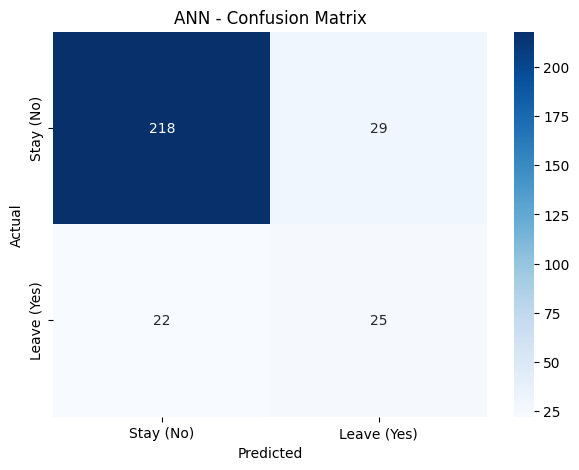

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Stay (No)", "Leave (Yes)"],
    yticklabels=["Stay (No)", "Leave (Yes)"]
)

plt.title("ANN - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

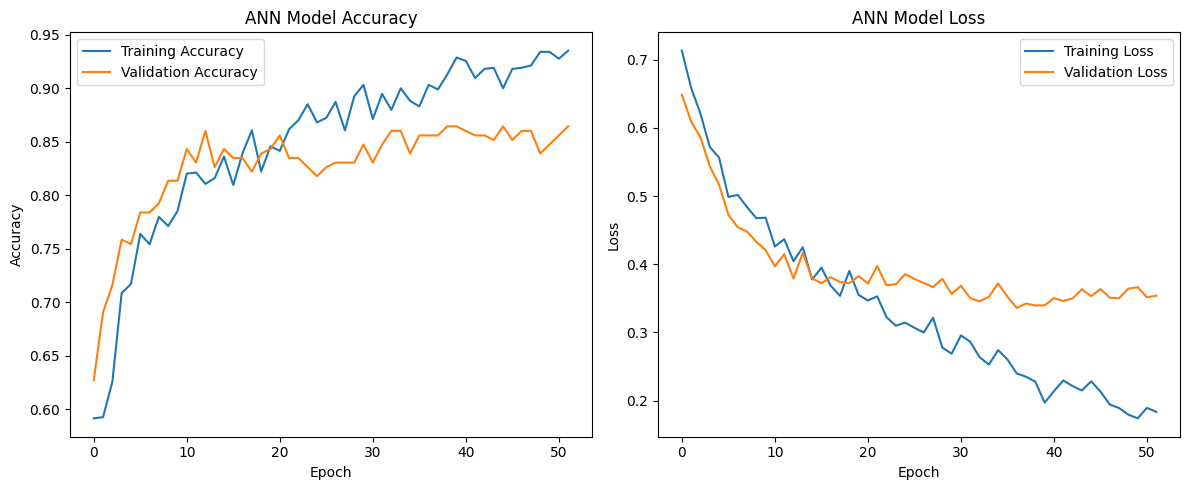

In [20]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("ANN Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("ANN Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [21]:
ann_model.save("AttriPredict_ANN_Model.keras")

print("ANN Model Saved Successfully!")

ANN Model Saved Successfully!


In [22]:
import joblib

joblib.dump(encoder, "AttriPredict_Encoder.pkl")
joblib.dump(scaler, "AttriPredict_Scaler.pkl")

print("Encoder Saved Successfully!")
print("Scaler Saved Successfully!")

Encoder Saved Successfully!
Scaler Saved Successfully!


In [23]:
from google.colab import files

files.download("AttriPredict_ANN_Model.keras")
files.download("AttriPredict_Encoder.pkl")
files.download("AttriPredict_Scaler.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [24]:
joblib.dump(
    {
        "numerical_columns": numerical_cols,
        "categorical_columns": categorical_cols
    },
    "AttriPredict_Feature_Columns.pkl"
)

print("Feature Columns Saved Successfully!")

Feature Columns Saved Successfully!


In [25]:
from google.colab import files

files.download("AttriPredict_Feature_Columns.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [26]:
sample_employee = X_test_final[0:1]

prediction_probability = ann_model.predict(sample_employee, verbose=0)[0][0]

prediction = "Leave (Yes)" if prediction_probability >= 0.5 else "Stay (No)"

print("EMPLOYEE ATTRITION PREDICTION")
print("--------------------------------")
print("Prediction:", prediction)
print("Attrition Probability:", round(float(prediction_probability) * 100, 2), "%")

EMPLOYEE ATTRITION PREDICTION
--------------------------------
Prediction: Stay (No)
Attrition Probability: 14.36 %


In [27]:
actual_value = int(y_test.iloc[0]) if hasattr(y_test, "iloc") else int(y_test[0])

actual_label = "Leave (Yes)" if actual_value == 1 else "Stay (No)"

print("ACTUAL RESULT:", actual_label)
print("PREDICTED RESULT:", prediction)

if actual_label == prediction:
    print("Prediction Status: CORRECT")
else:
    print("Prediction Status: INCORRECT")

ACTUAL RESULT: Stay (No)
PREDICTED RESULT: Stay (No)
Prediction Status: CORRECT


In [28]:
for i in range(10):
    probability = ann_model.predict(
        X_test_final[i:i+1], verbose=0
    )[0][0]

    predicted = 1 if probability >= 0.5 else 0
    actual = int(y_test.iloc[i]) if hasattr(y_test, "iloc") else int(y_test[i])

    print(
        f"Employee {i+1}: "
        f"Actual={actual}, "
        f"Predicted={predicted}, "
        f"Probability={probability*100:.2f}%"
    )

Employee 1: Actual=0, Predicted=0, Probability=14.36%
Employee 2: Actual=0, Predicted=0, Probability=0.46%
Employee 3: Actual=0, Predicted=0, Probability=34.47%
Employee 4: Actual=0, Predicted=0, Probability=0.68%
Employee 5: Actual=1, Predicted=1, Probability=82.22%
Employee 6: Actual=0, Predicted=0, Probability=16.15%
Employee 7: Actual=0, Predicted=0, Probability=2.69%
Employee 8: Actual=0, Predicted=0, Probability=20.57%
Employee 9: Actual=0, Predicted=0, Probability=1.61%
Employee 10: Actual=0, Predicted=0, Probability=23.74%
